In [2]:
from utils.swbd_disfluency_loader import Config, SwbdDisfluencyDataset
import ast, os, re, glob, json, difflib, statistics
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
import pandas as pd
from pathlib import Path

cfg = Config(
    zayats_tsv = r"C:\\exam scans\\ML PROJECT\\code\\switchboard_corrected_with_silver_reannotation.tsv",
    nxt_dir = r"C:\\exam scans\\ML PROJECT\\code\\nxt_switchboard_ann\\xml", # ... or anything else you want to override
)

path = Path("swbd_disfluency.jsonl")
if path.exists():
    print("Loading existing dataset...")
    ds = SwbdDisfluencyDataset.from_jsonl(path)
else:
    print("Building dataset...")
    ds = SwbdDisfluencyDataset(cfg).build()
    ds.save_jsonl(path)

final_df = ds.to_pandas()

c:\Users\nooro\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading existing dataset...


In [3]:
final_df.head(50)

,conv,file,speaker,turn,sent_num,nxt_speaker,align_agreement,swapped,enriched,tokens,...,typ,sil_after,fluent,disfluent,fluent_tokens,disfluent_tokens,disfl_labels,n_tokens_fluent,n_tokens_disfluent,n_disfl_tokens
0,sw2005,sw2005.trans,A,1,0,A,0.984,False,True,[okay],...,[None],[],okay,okay,[okay],[okay],[None],1,1,0
1,sw2005,sw2005.trans,A,1,1,A,0.984,False,True,"[uh, first, um, i, need, to, know, uh, h-, how...",...,"[filled_pause, None, filled_pause, None, None,...","[0, 1, 2, 6, 7, 13, 14, 16, 17, 19, 20]",first i need to know how do you feel about sen...,uh <sil> first <sil> um <sil> i need to know <...,"[first, i, need, to, know, how, do, you, feel,...","[uh, <sil>, first, <sil>, um, <sil>, i, need, ...","[filled_pause, silent_pause, None, silent_paus...",19,38,19
2,sw2005,sw2005.trans,B,2,0,B,0.980,False,True,"[well, of, course, it, 's, you, know, it, 's, ...",...,"[insertion, None, None, None, None, None, None...","[0, 2, 4, 6, 24, 30, 32, 33, 35, 37, 39, 40, 42]",of course you know it's it one of the last few...,well <sil> of course <sil> it's <sil> you know...,"[of, course, you, know, it, 's, it, one, of, t...","[well, <sil>, of, course, <sil>, it, 's, <sil>...","[insertion, silent_pause, None, None, silent_p...",40,60,20
3,sw2005,sw2005.trans,A,3,0,A,0.984,False,True,[yes],...,[None],[],yes,yes,[yes],[yes],[None],1,1,0
4,sw2005,sw2005.trans,A,3,1,A,0.984,False,True,[yeah],...,[None],[],yeah,yeah,[yeah],[yeah],[None],1,1,0
5,sw2005,sw2005.trans,B,4,0,B,0.980,False,True,"[i, 'd, be, very, very, careful, and, uh, you,...",...,"[None, None, None, None, None, None, None, fil...","[6, 7, 9]",i'd be very very careful you know checking the...,i'd be very very careful and <sil> uh <sil> yo...,"[i, 'd, be, very, very, careful, you, know, ch...","[i, 'd, be, very, very, careful, and, <sil>, u...","[None, None, None, None, None, None, reparandu...",11,16,5
6,sw2005,sw2005.trans,B,4,1,B,0.980,False,True,"[uh, our]",...,"[filled_pause, None]","[0, 1]",our,uh <sil> our <sil>,[our],"[uh, <sil>, our, <sil>]","[filled_pause, silent_pause, None, silent_pause]",1,4,3
7,sw2005,sw2005.trans,B,4,2,B,0.980,False,True,"[had, t-, place, my, mother, in, a, nursing, h...",...,"[None, None, None, None, None, None, None, Non...",[1],had place my mother in a nursing home,had t- <sil> place my mother in a nursing home,"[had, place, my, mother, in, a, nursing, home]","[had, t-, <sil>, place, my, mother, in, a, nur...","[None, fragment, silent_pause, None, None, Non...",8,10,2
8,sw2005,sw2005.trans,A,5,0,A,0.984,False,True,[um-hum],...,[None],[],um-hum,um-hum,[um-hum],[um-hum],[None],1,1,0
9,sw2005,sw2005.trans,B,6,0,B,0.980,False,True,"[and, uh, we, were, i, was, fortunate, in, that]",...,"[None, filled_pause, None, None, None, None, N...","[0, 1, 3]",and i was fortunate in that,and <sil> uh <sil> we were <sil> i was fortuna...,"[and, i, was, fortunate, in, that]","[and, <sil>, uh, <sil>, we, were, <sil>, i, wa...","[None, silent_pause, filled_pause, silent_paus...",6,12,6


In [4]:
final_df[['fluent', 'disfluent']].head(50) # sentences for training (?)

,fluent,disfluent
0,okay,okay
1,first i need to know how do you feel about sen...,uh <sil> first <sil> um <sil> i need to know <...
2,of course you know it's it one of the last few...,well <sil> of course <sil> it's <sil> you know...
3,yes,yes
4,yeah,yeah
5,i'd be very very careful you know checking the...,i'd be very very careful and <sil> uh <sil> yo...
6,our,uh <sil> our <sil>
7,had place my mother in a nursing home,had t- <sil> place my mother in a nursing home
8,um-hum,um-hum
9,and i was fortunate in that,and <sil> uh <sil> we were <sil> i was fortuna...


In [5]:
final_df[['tokens', 'bio', 'typ', 'sil_after']].head(50) # different tags for tokens

,tokens,bio,typ,sil_after
0,[okay],[O],[None],[]
1,"[uh, first, um, i, need, to, know, uh, h-, how...","[O, O, O, O, O, O, O, O, BE_IP, C, O, O, O, BE...","[filled_pause, None, filled_pause, None, None,...","[0, 1, 2, 6, 7, 13, 14, 16, 17, 19, 20]"
2,"[well, of, course, it, 's, you, know, it, 's, ...","[O, O, O, BE, IP, C, C, C, C, O, O, O, O, O, O...","[insertion, None, None, None, None, None, None...","[0, 2, 4, 6, 24, 30, 32, 33, 35, 37, 39, 40, 42]"
3,[yes],[O],[None],[]
4,[yeah],[O],[None],[]
5,"[i, 'd, be, very, very, careful, and, uh, you,...","[O, O, O, O, O, O, BE_IP, O, O, O, O, O, O]","[None, None, None, None, None, None, None, fil...","[6, 7, 9]"
6,"[uh, our]","[O, O]","[filled_pause, None]","[0, 1]"
7,"[had, t-, place, my, mother, in, a, nursing, h...","[O, O, O, O, O, O, O, O, O]","[None, None, None, None, None, None, None, Non...",[1]
8,[um-hum],[O],[None],[]
9,"[and, uh, we, were, i, was, fortunate, in, that]","[O, O, BE, IP, C, C, O, O, O]","[None, filled_pause, None, None, None, None, N...","[0, 1, 3]"


# Analysis

In [6]:
import ast, os, re, glob, json, difflib, statistics
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = final_df.copy()

# list columns are stored as strings -> parse once, robustly
LIST_COLS = ["tokens","bio","typ","sil_after","fluent_tokens","disfluent_tokens","disfl_labels"]
def parse_list(x):
    if isinstance(x, list): return x
    try: return ast.literal_eval(str(x))
    except Exception: return []
for c in LIST_COLS:
    if c in df.columns: df[c] = df[c].apply(parse_list)

TYPICAL  = {"filled_pause", "silent_pause"}
ATYPICAL = {"reparandum", "fragment", "insertion"}

df["n_typical"]  = df["disfl_labels"].apply(lambda L: sum(t in TYPICAL  for t in L))
df["n_atypical"] = df["disfl_labels"].apply(lambda L: sum(t in ATYPICAL for t in L))
df["n_sil"]      = df["disfl_labels"].apply(lambda L: L.count("silent_pause"))
df["disfl_rate"] = df["n_disfl_tokens"] / df["n_tokens_disfluent"].clip(lower=1)

In [7]:
# df = df[df["n_tokens_fluent"] >= 10]

print(f"Total utterances: {len(df):,}")
print(f"Average words (Fluent): {df['n_tokens_fluent'].mean():.1f}")
print(f"Average words (Disfluent): {df['n_tokens_disfluent'].mean():.1f}")
print(f"Average disfluencies per sentence: {df['n_disfl_tokens'].mean():.1f}")

Total utterances: 174,328
Average words (Fluent): 6.1
Average words (Disfluent): 7.3
Average disfluencies per sentence: 1.2


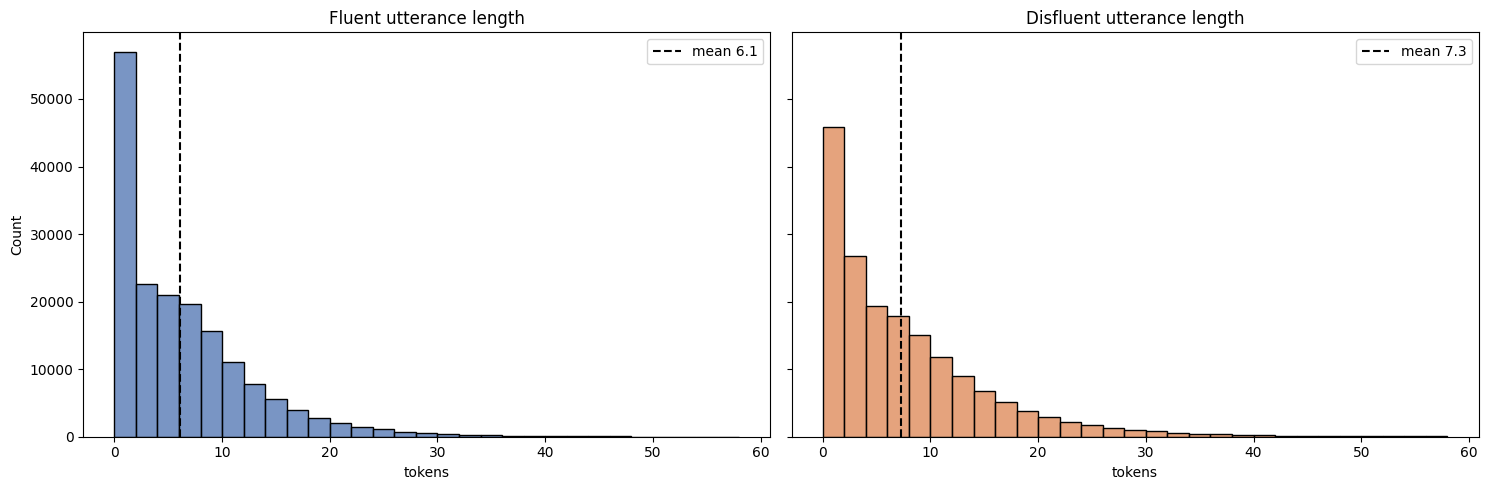

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a, (col, color, name) in zip(ax, [("n_tokens_fluent","#4C72B0","Fluent"),
                                      ("n_tokens_disfluent","#DD8452","Disfluent")]):
    # vals = df.loc[df[col] > 0, col]
    sns.histplot(df[col], bins=range(0, 60, 2), color=color, ax=a)
    a.axvline(df[col].mean(), color="k", ls="--", lw=1.5,
              label=f"mean {df[col].mean():.1f}")
    a.set_title(f"{name} utterance length"); a.set_xlabel("tokens"); a.legend()
plt.tight_layout(); plt.show()

In [9]:
# flatten all the lists into one giant list
all_disfluencies = [
    label
    for sublist in df['disfl_labels']
    for label in sublist
    if label is not None # ignoring clean
]

# count and display the occurrences
disfluency_counts = pd.Series(all_disfluencies).value_counts()

print("Disfluency Type Breakdown:")
print(disfluency_counts)
print(f"\nTotal disfluency tags counted: {len(all_disfluencies):,}")

Disfluency Type Breakdown:
silent_pause    102837
reparandum       68113
filled_pause     30692
insertion         6162
fragment          1702
Name: count, dtype: int64

Total disfluency tags counted: 209,506


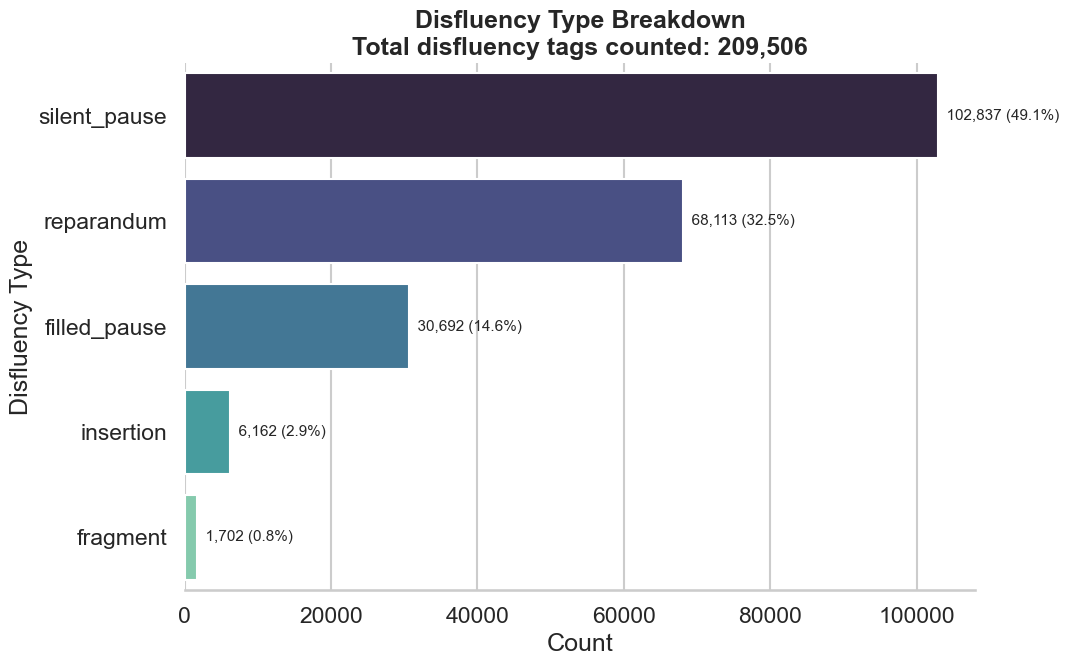

In [10]:
sns.set_theme(style="whitegrid", context="talk")
plot_df = disfluency_counts.reset_index()
plot_df.columns = ["Disfluency Type", "Count"]

# add percentages
total = plot_df["Count"].sum()
plot_df["Percent"] = plot_df["Count"] / total * 100
plot_df["Label"] = plot_df.apply(
    lambda row: f"{row['Count']:,} ({row['Percent']:.1f}%)",
    axis=1
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=plot_df,
    y="Disfluency Type",
    x="Count",
    hue="Disfluency Type",
    palette="mako",
    legend=False
)

plt.title(
    f"Disfluency Type Breakdown\nTotal disfluency tags counted: {total:,}",
    fontsize=18,
    weight="bold"
)
plt.xlabel("Count")
plt.ylabel("Disfluency Type")

# add count + percentage labels
for i, row in plot_df.iterrows():
    ax.text(
        row["Count"],
        i,
        f"  {row['Label']}",
        va="center",
        fontsize=11
    )

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

In [11]:
df["disfluent_tokens_list"] = df["disfluent_tokens"].apply(lambda x: ast.literal_eval(str(x)))
df["disfl_labels_list"] = df["disfl_labels"].apply(lambda x: ast.literal_eval(str(x)))
# df = df[df["disfluent_tokens_list"].apply(len) > 4]

tags = sorted({
    label
    for labels in df["disfl_labels_list"]
    for label in labels
    if label is not None
})

for tag in tags:
    print("\n" + "=" * 100)
    print(f"Examples for tag: {tag}")
    print("=" * 100)

    matching = df[
        df["disfl_labels_list"].apply(lambda labels: tag in labels)
    ]

    examples = matching.sample(
        n=min(5, len(matching)),
        random_state=42
    )

    for ex_num, (_, row) in enumerate(examples.iterrows(), start=1):
        print(f"\nExample {ex_num}")
        print("Disfluent:", row["disfluent"])
        print("Fluent:   ", row["fluent"])

        tagged_tokens = [
            f"{tok}<{label}>"
            for tok, label in zip(row["disfluent_tokens_list"], row["disfl_labels_list"])
            if label == tag
        ]

        print(f"{tag} token(s):", " ".join(tagged_tokens))


Examples for tag: filled_pause

Example 1
Disfluent: that or <sil> or <sil> uh <sil> the other extreme <sil>
Fluent:    that or the other extreme
filled_pause token(s): uh<filled_pause>

Example 2
Disfluent: i think that uh you know you can just look at home life and see
Fluent:    i think that you know you can just look at home life and see
filled_pause token(s): uh<filled_pause>

Example 3
Disfluent: they uh well they'll serve you at your seat
Fluent:    well they'll serve you at your seat
filled_pause token(s): uh<filled_pause>

Example 4
Disfluent: what they well you probably know a pace group that <sil> uh <sil> they're advanced type the they're special <sil> uh <sil> classes for pace classes
Fluent:    you probably know a pace group that they're special classes for pace classes
filled_pause token(s): uh<filled_pause> uh<filled_pause>

Example 5
Disfluent: and then i kind of hear it goes into like uh this is just something i've heard that it kind of goes into like uh just your of

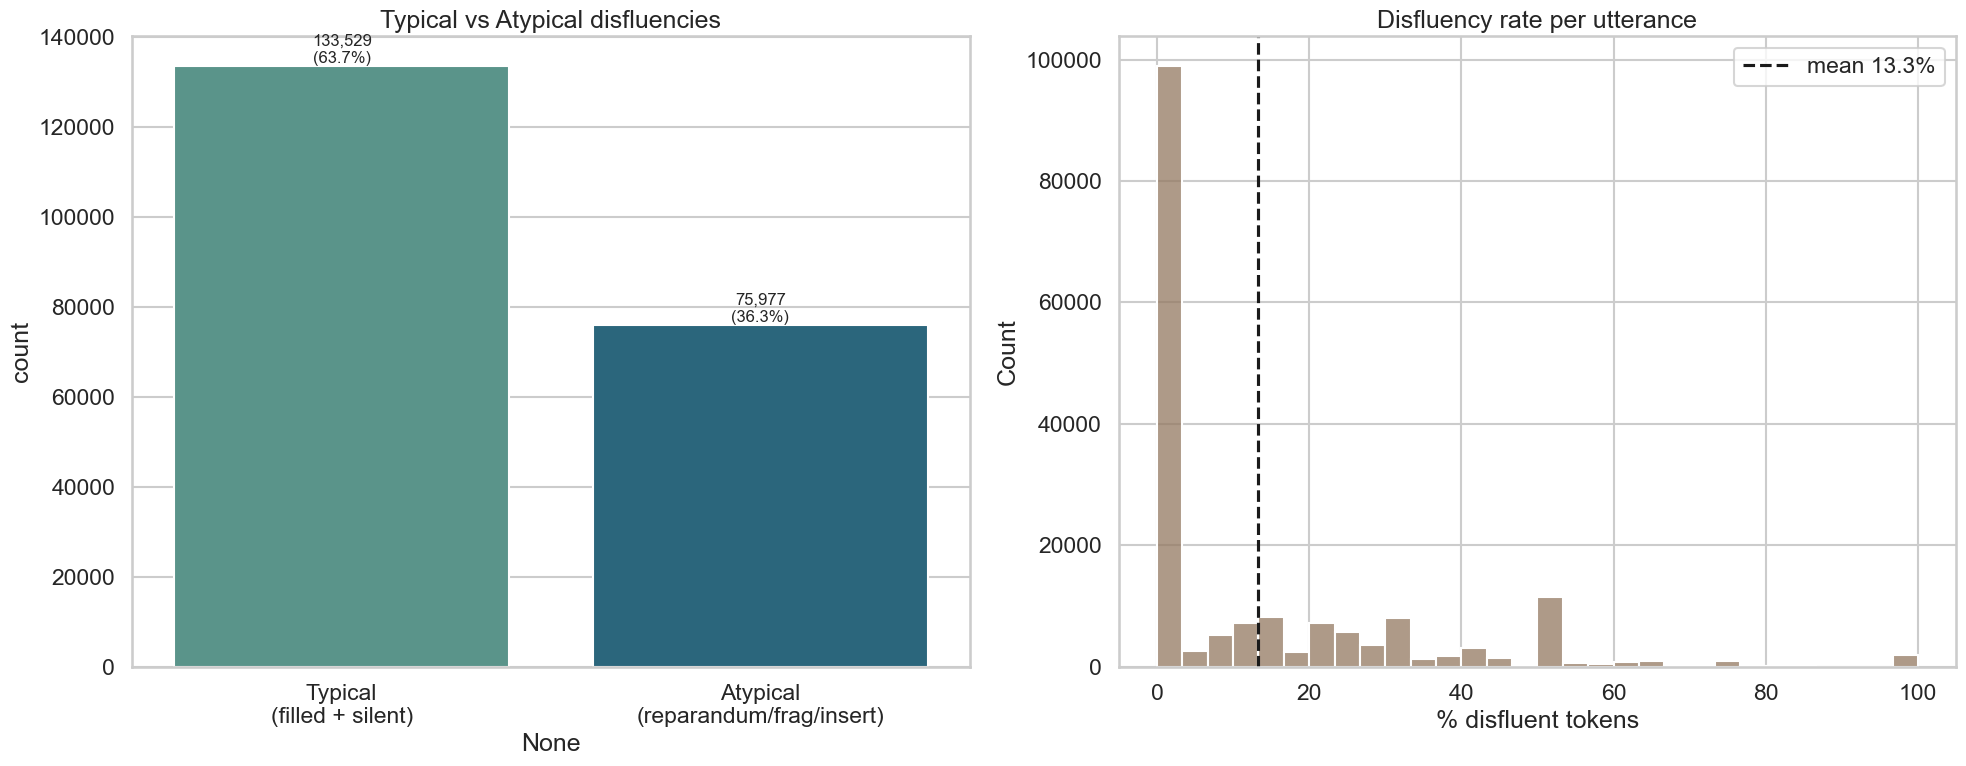

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
tot_typ, tot_atyp = df["n_typical"].sum(), df["n_atypical"].sum()

comp = pd.Series({"Typical\n(filled + silent)": tot_typ, "Atypical\n(reparandum/frag/insert)": tot_atyp})
sns.barplot(x=comp.index, y=comp.values, hue=comp.index, palette="crest", legend=False, ax=ax[0])

for i, v in enumerate(comp.values):
    ax[0].text(i, v, f"{v:,}\n({100*v/comp.sum():.1f}%)", ha="center", va="bottom", fontsize=12)
ax[0].set_title("Typical vs Atypical disfluencies"); ax[0].set_ylabel("count")

vals = df.loc[df["disfl_rate"] >= 0, "disfl_rate"]

sns.histplot(vals*100, bins=30, color="#937860", ax=ax[1])
ax[1].axvline(vals.mean()*100, color="k", ls="--",
              label=f"mean {df['disfl_rate'].mean()*100:.1f}%")
ax[1].set_title("Disfluency rate per utterance"); ax[1].set_xlabel("% disfluent tokens"); ax[1].legend()
plt.tight_layout(); plt.show()

Dataset Split / Leakage Check

    This matters because for train/test splitting, it is safer to split by conversation, not random rows, so the same dialogue does not appear in both train and test.

In [13]:
# Conversation-level summary for split planning

conv_summary = (
    df.groupby("conv")
    .agg(
        n_utterances=("conv", "size"),
        n_speakers=("speaker", "nunique"),
        avg_disfl_tokens=("n_disfl_tokens", "mean"),
        avg_fluent_len=("n_tokens_fluent", "mean"),
        avg_disfluent_len=("n_tokens_disfluent", "mean"),
    )
    .reset_index()
)

print(f"Number of conversations: {conv_summary['conv'].nunique():,}")
print(f"Total utterances: {len(df):,}")
print(f"Average utterances per conversation: {conv_summary['n_utterances'].mean():.1f}")
print(f"Median utterances per conversation: {conv_summary['n_utterances'].median():.1f}")

conv_summary.sort_values("n_utterances", ascending=False).head(10)

Number of conversations: 1,126
Total utterances: 174,328
Average utterances per conversation: 154.8
Median utterances per conversation: 137.0


,conv,n_utterances,n_speakers,avg_disfl_tokens,avg_fluent_len,avg_disfluent_len
173,sw2427,400,2,0.842500,4.302500,5.145000
372,sw2830,396,2,0.315657,5.297980,5.613636
413,sw2921,376,2,0.428191,4.776596,5.204787
23,sw2061,371,2,1.487871,4.935310,6.423181
279,sw2621,364,2,0.398352,5.392857,5.791209
264,sw2598,361,2,1.936288,5.185596,7.121884
441,sw2970,355,2,1.538028,5.653521,7.191549
282,sw2627,354,2,1.466102,5.135593,6.601695
410,sw2913,353,2,1.325779,5.354108,6.679887
204,sw2479,352,2,1.156250,5.073864,6.230114


Conversation Size Plot

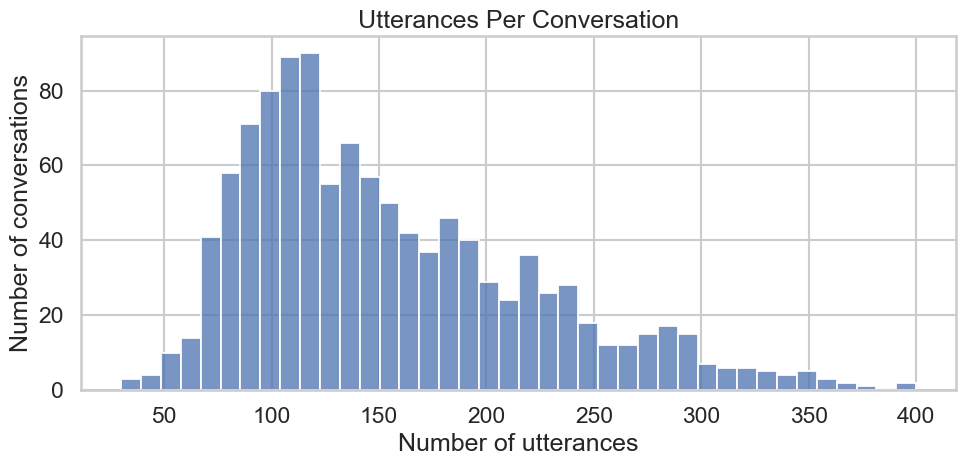

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(conv_summary["n_utterances"], bins=40, color="#4C72B0")

plt.title("Utterances Per Conversation")
plt.xlabel("Number of utterances")
plt.ylabel("Number of conversations")
plt.tight_layout()
plt.show()

    Takeaway: the dataset is fairly well distributed across conversations, not dominated by only a few huge ones. Conversation-level splitting should work well.

Disfluencies Per Utterance

Disfluencies per utterance:
n_disfl_tokens
0     98724
1     33783
2     13489
3      9877
4      5685
5      3917
6      2634
7      1773
8      1217
9       883
10      611
11      450
12      305
13      238
14      193
15      109
16       98
17       61
18       69
19       40
Name: count, dtype: int64


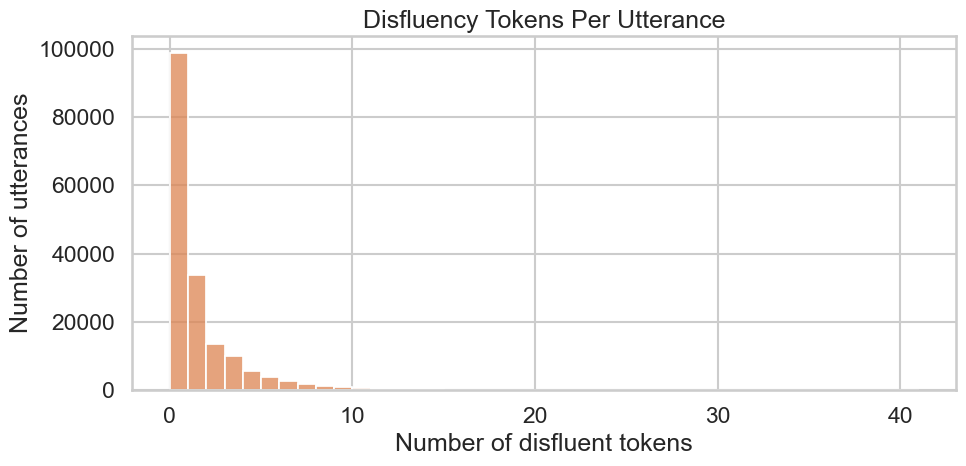

In [15]:
disfl_per_utt = df["n_disfl_tokens"].value_counts().sort_index()

print("Disfluencies per utterance:")
print(disfl_per_utt.head(20))

plt.figure(figsize=(10, 5))

sns.histplot(df["n_disfl_tokens"], bins=range(0, min(df["n_disfl_tokens"].max(), 40) + 2), color="#DD8452")

plt.title("Disfluency Tokens Per Utterance")
plt.xlabel("Number of disfluent tokens")
plt.ylabel("Number of utterances")
plt.tight_layout()
plt.show()

Percent Of Sentences With No / Some / Many Disfluencies

In [16]:
def disfluency_bucket(n):
    if n == 0:
        return "0"
    if n <= 2:
        return "1-2"
    if n <= 5:
        return "3-5"
    return "6+"

df["disfluency_bucket"] = df["n_disfl_tokens"].apply(disfluency_bucket)

bucket_counts = df["disfluency_bucket"].value_counts().reindex(["0", "1-2", "3-5", "6+"])
bucket_percent = bucket_counts / bucket_counts.sum() * 100

bucket_table = pd.DataFrame({
    "count": bucket_counts,
    "percent": bucket_percent.round(2)
})

bucket_table

,count,percent
disfluency_bucket,,
0,98724,56.63
1-2,47272,27.12
3-5,19479,11.17
6+,8853,5.08


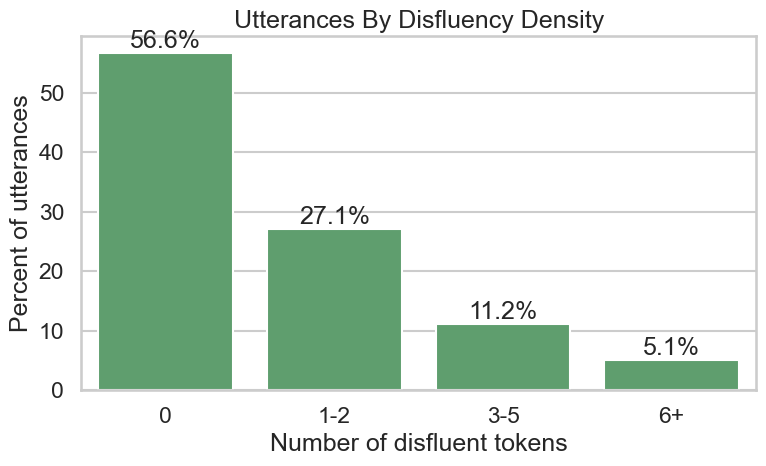

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=bucket_table.index,
    y=bucket_table["percent"],
    color="#55A868"
)

plt.title("Utterances By Disfluency Density")
plt.xlabel("Number of disfluent tokens")
plt.ylabel("Percent of utterances")

for i, value in enumerate(bucket_table["percent"]):
    plt.text(i, value, f"{value:.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

Examples From Low / Medium / High Disfluency Density

    supposed to help us inspect whether high-disfluency examples are still natural or whether they are too noisy for training/evaluation.

In [19]:
example_cols = ["fluent", "disfluent", "n_disfl_tokens", "disfl_labels"]

low_examples = df[df["disfluency_bucket"] == "1-2"][example_cols].sample(5, random_state=42)
medium_examples = df[df["disfluency_bucket"] == "3-5"][example_cols].sample(5, random_state=42)
high_examples = df[df["disfluency_bucket"] == "6+"][example_cols].sample(5, random_state=42)

print("LOW DISFLUENCY EXAMPLES")
display(low_examples)

print("MEDIUM DISFLUENCY EXAMPLES")
display(medium_examples)

print("HIGH DISFLUENCY EXAMPLES")
display(high_examples)

LOW DISFLUENCY EXAMPLES


,fluent,disfluent,n_disfl_tokens,disfl_labels
105256,yeah,yeah <sil>,1,"[None, silent_pause]"
21227,but redemption centers are a big thing up here,so but redemption centers are a big thing up here,1,"[reparandum, None, None, None, None, None, Non..."
151870,and as a society we are paying a staggering pr...,uh and uh as a society we are paying a stagger...,2,"[filled_pause, None, filled_pause, None, None,..."
62401,i'm going to have to get a map to figure out e...,i ha- i'm going to have to get a map to figure...,2,"[reparandum, reparandum, None, None, None, Non..."
156266,oh is that right,oh <sil> is that right,1,"[None, silent_pause, None, None, None]"


MEDIUM DISFLUENCY EXAMPLES


,fluent,disfluent,n_disfl_tokens,disfl_labels
79690,but i don't know,but <sil> i <sil> i don't know <sil>,4,"[None, silent_pause, reparandum, silent_pause,..."
164646,and of course now you know you go through two ...,and <sil> of course <sil> now <sil> you know <...,5,"[None, silent_pause, None, None, silent_pause,..."
18633,my parents bought a home in san diego about fo...,my parents <sil> uh <sil> bought a home in san...,4,"[None, None, silent_pause, filled_pause, silen..."
31467,let me see,um let me see let me see,4,"[filled_pause, reparandum, reparandum, reparan..."
23664,so it's business,and and it's so it's business,4,"[reparandum, reparandum, reparandum, reparandu..."


HIGH DISFLUENCY EXAMPLES


,fluent,disfluent,n_disfl_tokens,disfl_labels
48452,and we're just real concerned about this incin...,and we're just we're just real concerned about...,8,"[None, reparandum, reparandum, reparandum, Non..."
161564,and when i was in high school we used to go bo...,and we used to <sil> when i was in high school...,8,"[None, reparandum, reparandum, reparandum, sil..."
2134,yeah we set a record yesterday very windy,yeah we set a record yesterday and <sil> uh <s...,6,"[None, None, None, None, None, None, reparandu..."
47272,so you can still good house for a very very re...,so you can still get a <sil> get a <sil> a g- ...,9,"[None, None, None, None, reparandum, reparandu..."
46196,i guess it all comes down to you know a defini...,it it uh i guess it all comes down to uh you k...,7,"[reparandum, reparandum, filled_pause, None, N..."
